In [1]:
!pip install -q datasets

In [8]:
# STEP 1: Load CIFAR-10 from Hugging Face

from datasets import load_dataset
from torchvision import transforms
from torch.utils.data import DataLoader
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Load dataset
dataset = load_dataset("uoft-cs/cifar10")

# Convert PIL images to tensors
transform = transforms.ToTensor()

def convert(example):
    example["img"] = [transform(img) for img in example["img"]]
    return example

# Apply transformation
dataset = dataset.with_transform(convert)

# DataLoader
train_loader = DataLoader(
    dataset["train"],
    batch_size=128,
    shuffle=True
)

print("CIFAR-10 loaded successfully!")

CIFAR-10 loaded successfully!


In [3]:
class VAE(nn.Module):

    def __init__(self):
        super().__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1),
            nn.ReLU(),
            nn.Conv2d(32, 64, 4, 2, 1),
            nn.ReLU(),
            nn.Flatten()
        )

        self.mu = nn.Linear(64 * 8 * 8, 64)
        self.logvar = nn.Linear(64 * 8 * 8, 64)

        # Decoder
        self.fc = nn.Linear(64, 64 * 8 * 8)

        self.decoder = nn.Sequential(
            nn.Unflatten(1, (64, 8, 8)),
            nn.ConvTranspose2d(64, 32, 4, 2, 1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 4, 2, 1),
            nn.Sigmoid()
        )

    def encode(self, x):
        x = self.encoder(x)
        return self.mu(x), self.logvar(x)

    def decode(self, z):
        return self.decoder(self.fc(z))

    def forward(self, x):

        mu, logvar = self.encode(x)

        # Reparameterization
        std = torch.exp(0.5 * logvar)
        noise = torch.randn_like(std)

        z = mu + noise * std

        output = self.decode(z)

        return output, mu, logvar

In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"

vae = VAE().to(device)

print("VAE created!")

VAE created!


In [5]:
optimizer = torch.optim.Adam(
    vae.parameters(),
    lr=0.001
)

In [6]:
def loss_function(output, image, mu, logvar):

    reconstruction_loss = F.mse_loss(
        output,
        image,
        reduction="sum"
    )

    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu**2 - logvar.exp()
    )

    return reconstruction_loss + kl_loss

In [9]:
for epoch in range(5):

    total_loss = 0

    for batch in train_loader:

        images = batch["img"].to(device)

        optimizer.zero_grad()

        output, mu, logvar = vae(images)

        loss = loss_function(
            output,
            images,
            mu,
            logvar
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    print(
        "Epoch:",
        epoch + 1,
        "Loss:",
        total_loss
    )

Epoch: 1 Loss: 5383598.978027344
Epoch: 2 Loss: 4050912.1645507812
Epoch: 3 Loss: 3944035.0415039062
Epoch: 4 Loss: 3894000.35546875
Epoch: 5 Loss: 3864048.9541015625


In [10]:
vae.eval()

# Create 16 random latent vectors
z = torch.randn(16, 64).to(device)

# Generate images
with torch.no_grad():
    new_images = vae.decode(z)

new_images = new_images.cpu()

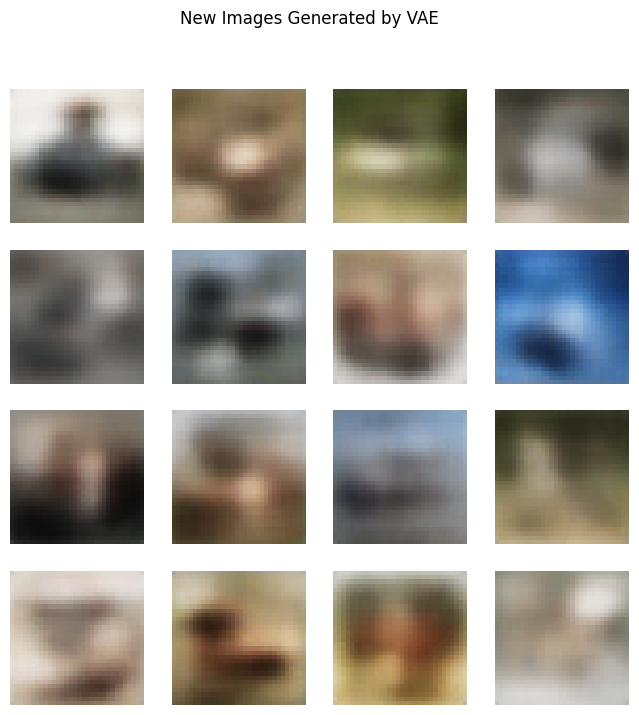

In [11]:
fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):

    image = new_images[i].permute(1, 2, 0)

    ax.imshow(image)

    ax.axis("off")

plt.suptitle("New Images Generated by VAE")
plt.show()

In [12]:
batch = next(iter(train_loader))

image1 = batch["img"][0:1].to(device)
image2 = batch["img"][1:2].to(device)

In [13]:
with torch.no_grad():

    z1, _ = vae.encode(image1)
    z2, _ = vae.encode(image2)

In [14]:
images = []

for alpha in torch.linspace(0, 1, 8):

    z = (1 - alpha) * z1 + alpha * z2

    with torch.no_grad():
        image = vae.decode(z)

    images.append(image.cpu())

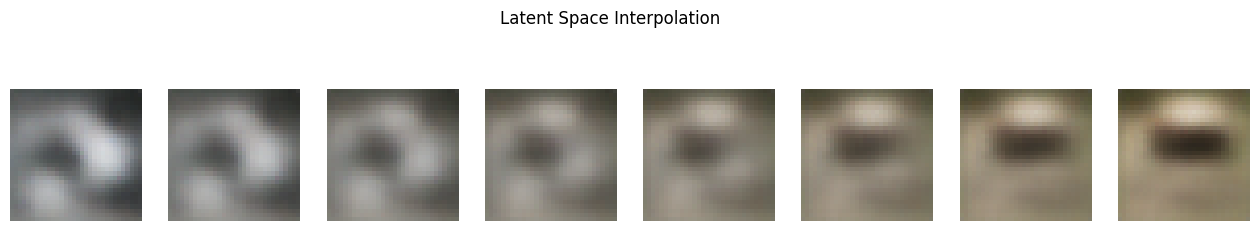

In [15]:
fig, axes = plt.subplots(1, 8, figsize=(16, 3))

for i in range(8):

    image = images[i][0].permute(1, 2, 0)

    axes[i].imshow(image)

    axes[i].axis("off")

plt.suptitle("Latent Space Interpolation")
plt.show()